<a href="https://colab.research.google.com/github/TI3G-PBL-House-Price/ml-model-testing/blob/random-forest/PBL_RandomForestRegressor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1. PEMAHAMAN DATA**

### **1.1 Import Library**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

### **1.2 Membaca Dataset**

In [ ]:
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/Semester 5/PBL/jakarta_house.csv')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **1.3 Menampilkan Data**

In [ ]:
df.head()

,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


### **1.4 Mengetahui Ukuran Dataset**

In [ ]:
print("Jumlah baris :", df.shape[0])
print("Jumlah kolom :", df.shape[1])

Jumlah baris : 10000
Jumlah kolom : 9


### **1.5 Menampilkan Nama Kolom**

In [ ]:
print('===Nama Kolom===')
for col in df.columns:
    print(col)

===Nama Kolom===
index
price
district
city
bed_rooms
bath_rooms
carport
land_area
building_area


### **1.6 Mengecek Tipe Data**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          10000 non-null  int64  
 1   price          10000 non-null  int64  
 2   district       10000 non-null  object 
 3   city           10000 non-null  object 
 4   bed_rooms      10000 non-null  int64  
 5   bath_rooms     10000 non-null  int64  
 6   carport        10000 non-null  int64  
 7   land_area      9997 non-null   float64
 8   building_area  9995 non-null   float64
dtypes: float64(2), int64(5), object(2)
memory usage: 703.3+ KB


### **1.7 Mengecek Missing Value**

In [ ]:
df.isnull().sum()

,0
index,0
price,0
district,0
city,0
bed_rooms,0
bath_rooms,0
carport,0
land_area,3
building_area,5


### **1.8 Mengecek Data Duplikat**

In [ ]:
df.duplicated().sum()

print("Jumlah data duplikat :", df.duplicated().sum())

Jumlah data duplikat : 0


# **2. EXPLORATORY DATA ANALYSIS (EDA)**

### **2.1 Statistik Deskriptifk**

In [ ]:
df.describe()

,index,price,bed_rooms,bath_rooms,carport,land_area,building_area
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,9997.000000,9995.000000
mean,5000.50000,1.004029e+10,4.253500,3.521300,1.578900,296.610183,319.962481
std,2886.89568,2.004519e+10,3.176609,2.900136,1.743467,502.921686,357.676034
min,1.00000,1.850000e+06,0.000000,0.000000,0.000000,1.000000,1.000000
25%,2500.75000,2.500000e+09,3.000000,2.000000,1.000000,100.000000,139.000000
50%,5000.50000,4.500000e+09,4.000000,3.000000,1.000000,177.000000,230.000000
75%,7500.25000,9.800000e+09,5.000000,4.000000,2.000000,335.000000,400.000000
max,10000.00000,9.000000e+11,63.000000,63.000000,31.000000,17714.000000,15331.000000


### **2.2 Analisis Distribusi Data Numeric**

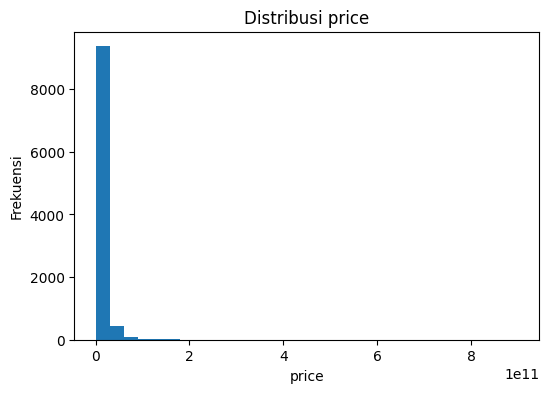

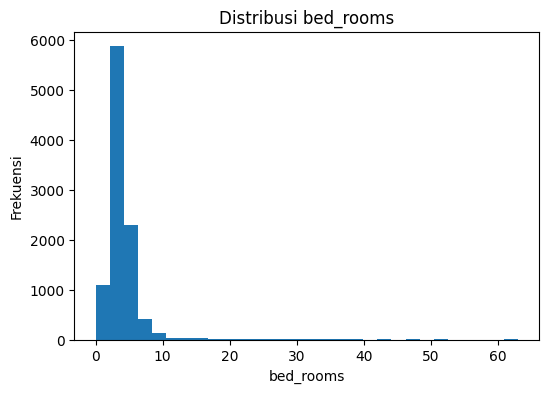

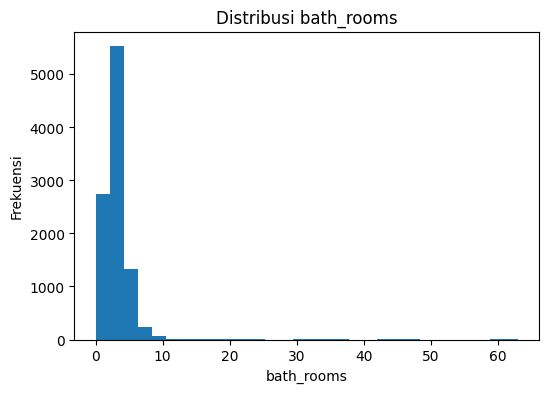

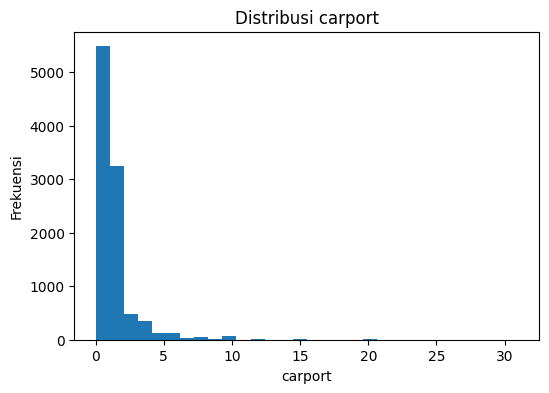

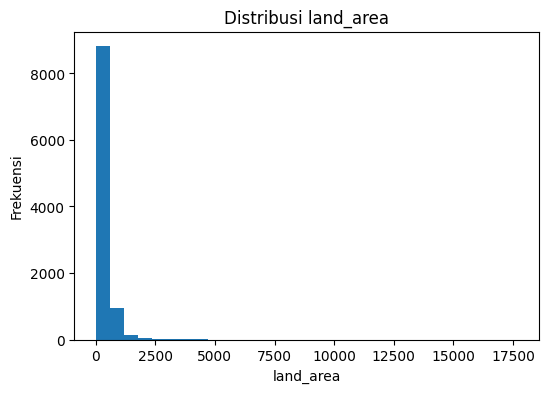

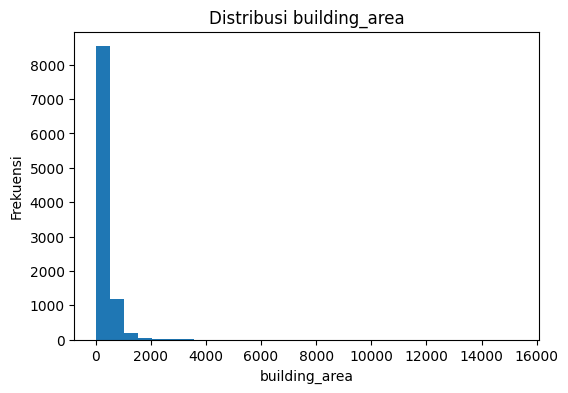

In [ ]:
num_cols = [
    'price',
    'bed_rooms',
    'bath_rooms',
    'carport',
    'land_area',
    'building_area'
]

for col in num_cols:
    plt.figure(figsize=(6,4))
    plt.hist(df[col], bins=30)
    plt.title(f'Distribusi {col}')
    plt.xlabel(col)
    plt.ylabel('Frekuensi')
    plt.show()

### **2.3 Analisis Distribusi City**

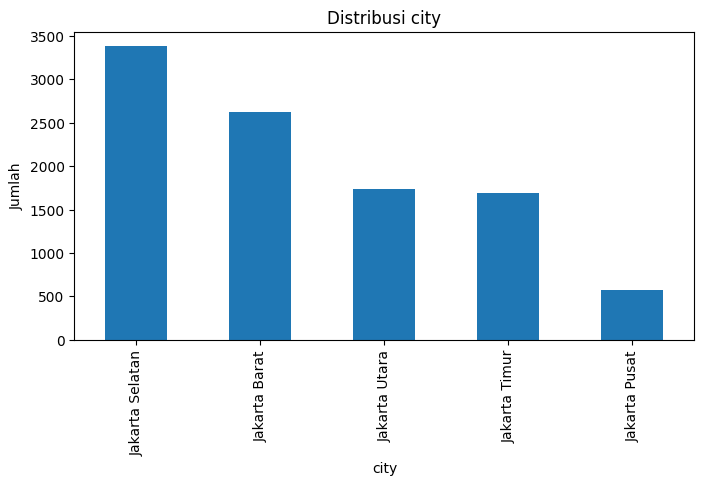

In [ ]:
cat_cols = ['city']

for col in cat_cols:
    plt.figure(figsize=(8,4))
    df[col].value_counts().plot(kind='bar')
    plt.title(f'Distribusi {col}')
    plt.xlabel(col)
    plt.ylabel('Jumlah')
    plt.show()

### **2.4 Visualisasi Outlier dengan Boxplot**

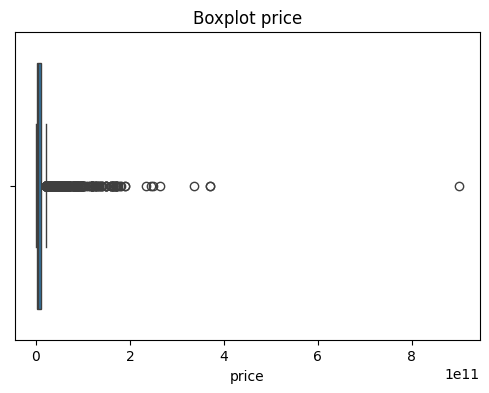

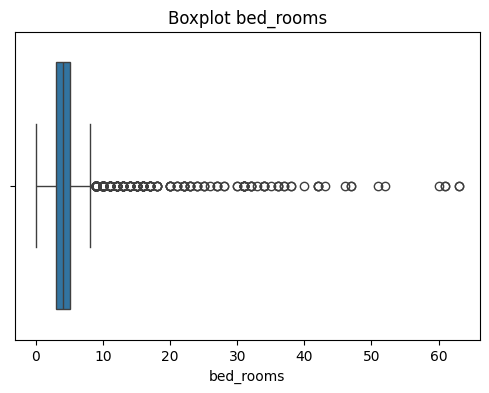

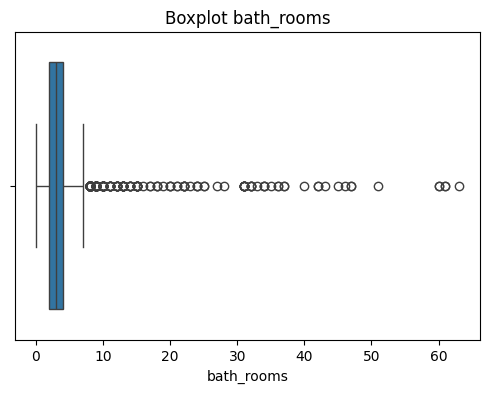

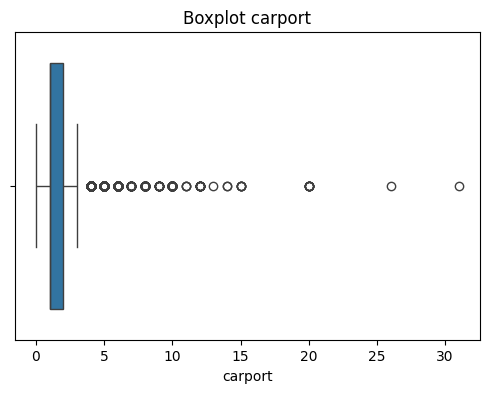

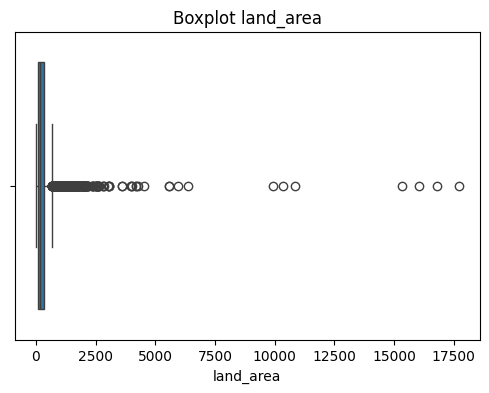

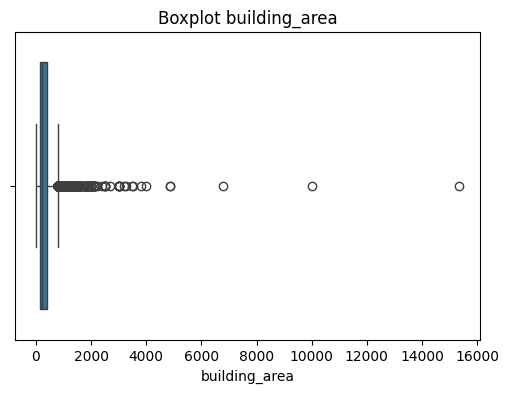

In [ ]:
for col in num_cols:
    plt.figure(figsize=(6,4))

    sns.boxplot(x=df[col])

    plt.title(f'Boxplot {col}')
    plt.show()

### **2.5 Korelasi Antar Fitur**

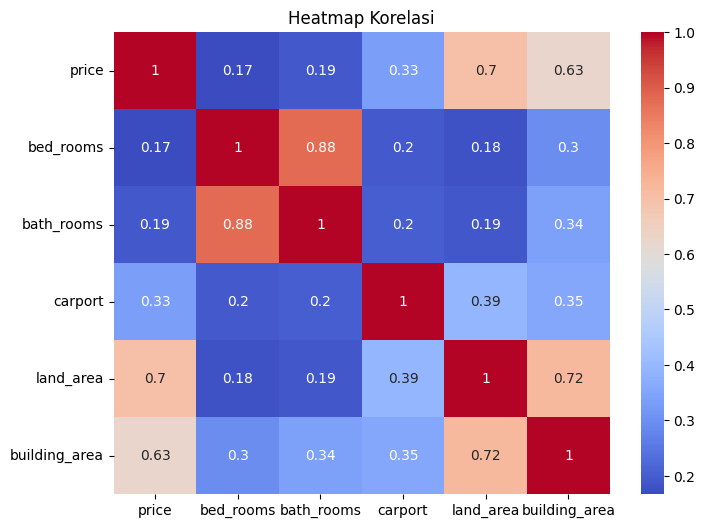

In [ ]:
corr = df[num_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)

plt.title('Heatmap Korelasi')
plt.show()

### **2.6 Korelasi Terhadap Target (Price)**

In [ ]:
corr['price'].sort_values(ascending=False)

,price
price,1.000000
land_area,0.698065
building_area,0.625742
carport,0.333620
bath_rooms,0.190966
bed_rooms,0.166950


# **3. PRA PENGOLAHAN DATA**

### **3.1 Data Imputation / Mengisi Missing Value**

In [ ]:
# Land Area - Mean
df['land_area'] = df['land_area'].fillna(df['land_area'].mean())

# Building Area - Mean
df['building_area'] = df['building_area'].fillna(df['building_area'].mean())



### **3.2 Validasi Hasil Imputasi**

In [ ]:
df.info()

print()

df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          10000 non-null  int64  
 1   price          10000 non-null  int64  
 2   district       10000 non-null  object 
 3   city           10000 non-null  object 
 4   bed_rooms      10000 non-null  int64  
 5   bath_rooms     10000 non-null  int64  
 6   carport        10000 non-null  int64  
 7   land_area      10000 non-null  float64
 8   building_area  10000 non-null  float64
dtypes: float64(2), int64(5), object(2)
memory usage: 703.3+ KB



,0
index,0
price,0
district,0
city,0
bed_rooms,0
bath_rooms,0
carport,0
land_area,0
building_area,0


### **3.3 Deteksi Outlier**

In [ ]:
# Menentukan Kolom Numerik
num_cols = [
    'price',
    'bed_rooms',
    'bath_rooms',
    'carport',
    'land_area',
    'building_area'
]

# Menghitung Nilai Q1, Q3, IQR, Batas Outlier, dan Jumlah Outlier
for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - (1.5 * IQR)
    batas_atas = Q3 + (1.5 * IQR)

    jumlah_outlier = df[
        (df[col] < batas_bawah) |
        (df[col] > batas_atas)
    ].shape[0]

    print(f"\n===== {col} =====")
    print("Q1 :", Q1)
    print("Q3 :", Q3)
    print("IQR :", IQR)
    print("Batas Bawah :", batas_bawah)
    print("Batas Atas :", batas_atas)
    print("Jumlah Outlier :", jumlah_outlier)


===== price =====
Q1 : 2500000000.0
Q3 : 9800000000.0
IQR : 7300000000.0
Batas Bawah : -8450000000.0
Batas Atas : 20750000000.0
Jumlah Outlier : 1107

===== bed_rooms =====
Q1 : 3.0
Q3 : 5.0
IQR : 2.0
Batas Bawah : 0.0
Batas Atas : 8.0
Jumlah Outlier : 308

===== bath_rooms =====
Q1 : 2.0
Q3 : 4.0
IQR : 2.0
Batas Bawah : -1.0
Batas Atas : 7.0
Jumlah Outlier : 270

===== carport =====
Q1 : 1.0
Q3 : 2.0
IQR : 1.0
Batas Bawah : -0.5
Batas Atas : 3.5
Jumlah Outlier : 795

===== land_area =====
Q1 : 100.0
Q3 : 335.0
IQR : 235.0
Batas Bawah : -252.5
Batas Atas : 687.5
Jumlah Outlier : 881

===== building_area =====
Q1 : 139.0
Q3 : 400.0
IQR : 261.0
Batas Bawah : -252.5
Batas Atas : 791.5
Jumlah Outlier : 656


### **3.4 Penanganan Outlier**

In [ ]:
# Menyimpan jumlah data awal
jumlah_awal = len(df)

while True:

    mask_outlier = pd.Series(False, index=df.index)

    for col in num_cols:

        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)

        IQR = Q3 - Q1

        batas_bawah = Q1 - (1.5 * IQR)
        batas_atas = Q3 + (1.5 * IQR)

        mask_outlier |= (
            (df[col] < batas_bawah) |
            (df[col] > batas_atas)
        )

    jumlah_outlier = mask_outlier.sum()

    print("Outlier ditemukan :", jumlah_outlier)

    if jumlah_outlier == 0:
        break

    df = df[~mask_outlier]

# Jumlah Data Setelah Penghapusan Outlier
print("Jumlah data sebelum :", jumlah_awal)
print("Jumlah data sesudah :", len(df))
print("Data yang terhapus :", jumlah_awal - len(df))

Outlier ditemukan : 1999
Outlier ditemukan : 1444
Outlier ditemukan : 773
Outlier ditemukan : 389
Outlier ditemukan : 284
Outlier ditemukan : 103
Outlier ditemukan : 63
Outlier ditemukan : 81
Outlier ditemukan : 0
Jumlah data sebelum : 10000
Jumlah data sesudah : 4864
Data yang terhapus : 5136


### **3.5 Validasi Hasil Penanganan Outlier**

In [ ]:
# Mengecek Jumlah Data Setelah Penghapusan
for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    batas_bawah = Q1 - (1.5 * IQR)
    batas_atas = Q3 + (1.5 * IQR)

    jumlah_outlier = df[
        (df[col] < batas_bawah) |
        (df[col] > batas_atas)
    ].shape[0]

    print(f"{col} : {jumlah_outlier}")


price : 0
bed_rooms : 0
bath_rooms : 0
carport : 0
land_area : 0
building_area : 0


### **3.6 Visualisasi Distribusi Data Setelah Penghapusan Outlier**

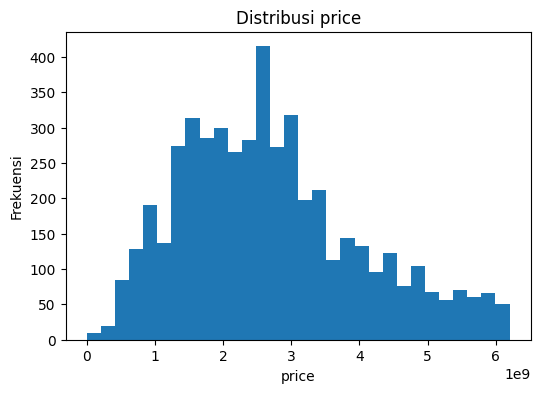

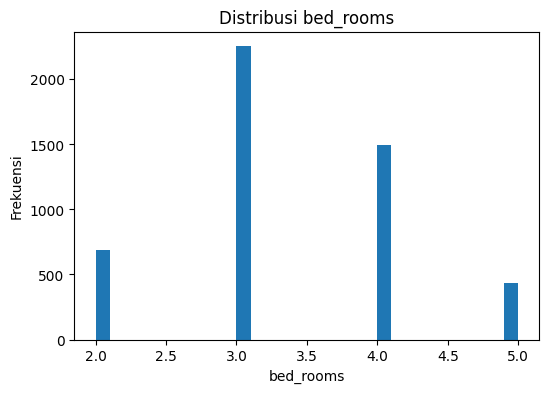

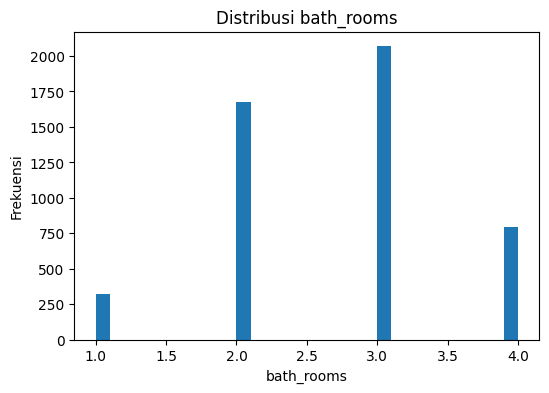

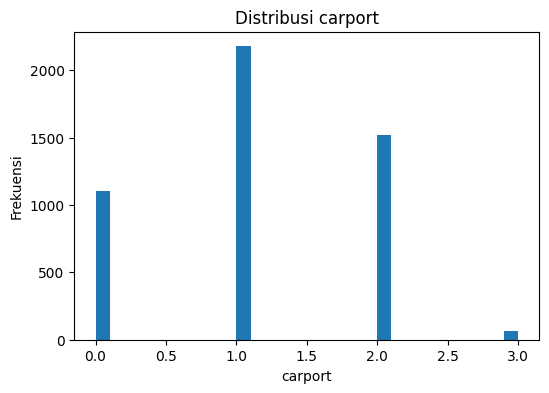

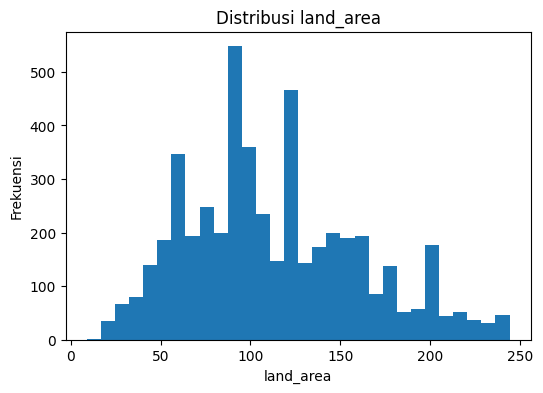

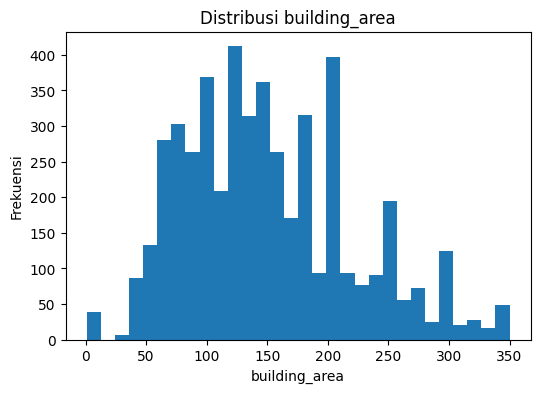

In [ ]:
num_cols = [
    'price',
    'bed_rooms',
    'bath_rooms',
    'carport',
    'land_area',
    'building_area'
]

for col in num_cols:
    plt.figure(figsize=(6,4))
    plt.hist(df[col], bins=30)
    plt.title(f'Distribusi {col}')
    plt.xlabel(col)
    plt.ylabel('Frekuensi')
    plt.show()

### **3.7 Visualisasi Boxplot Setelah Penghapusan Outlier**

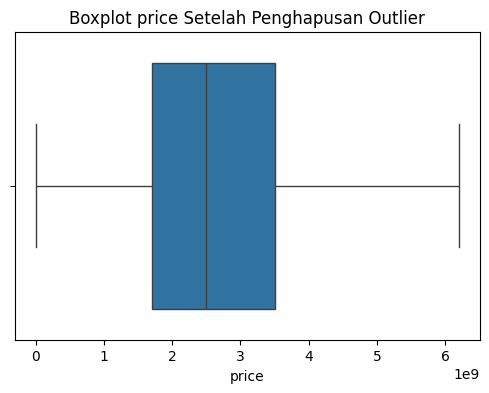

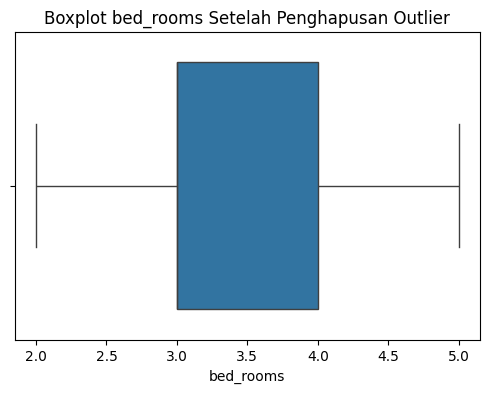

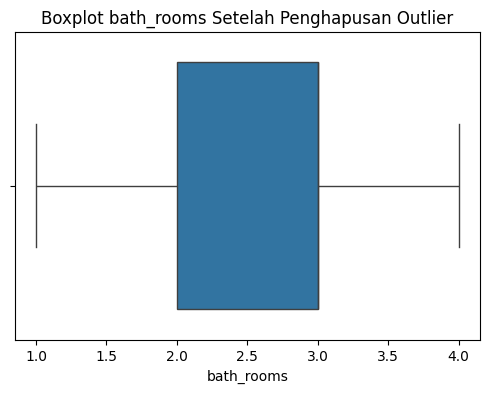

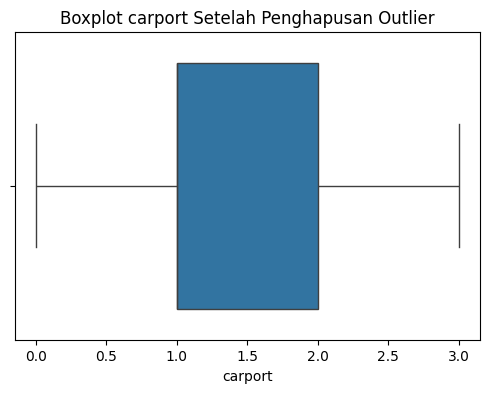

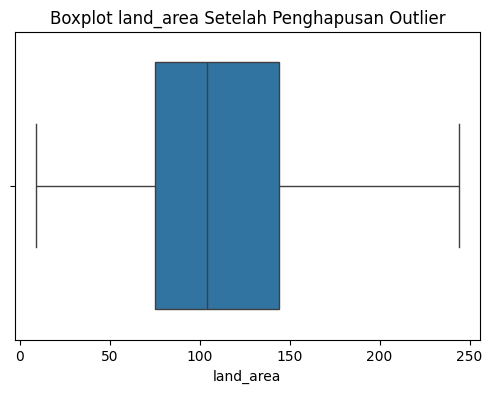

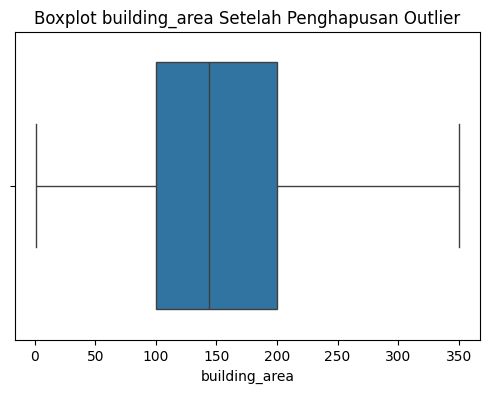

In [ ]:
for col in num_cols:

    plt.figure(figsize=(6,4))

    sns.boxplot(x=df[col])

    plt.title(f'Boxplot {col} Setelah Penghapusan Outlier')

    plt.show()

# **4. FEATURE ENGINEERING**

### **4.1 Membuat Fitur Total Ruangan**

In [ ]:
df['total_rooms'] = (df['bed_rooms'] +df['bath_rooms'])

### **4.2 Membuat Fitur Rasio Bangunan**

In [ ]:
df['building_ratio'] = (df['building_area'] /df['land_area'])

### **4.3 Membuat Fitur Sisa Lahan**

In [ ]:
df['remaining_land'] = (df['land_area'] - df['building_area'])

### **4.4 Membuat Fitur Total Fasiltas**

In [ ]:
df['total_facilities'] = (df['bed_rooms'] +df['bath_rooms'] +df['carport'])

### **4.5 Membuat Fitur Total Luas Properti**

In [ ]:
df['total_area'] = (df['land_area'] +df['building_area'])

### **4.6 Verifikasi Hasil Feature Engineering**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4864 entries, 1 to 9997
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   index             4864 non-null   int64  
 1   price             4864 non-null   int64  
 2   district          4864 non-null   object 
 3   city              4864 non-null   object 
 4   bed_rooms         4864 non-null   int64  
 5   bath_rooms        4864 non-null   int64  
 6   carport           4864 non-null   int64  
 7   land_area         4864 non-null   float64
 8   building_area     4864 non-null   float64
 9   total_rooms       4864 non-null   int64  
 10  building_ratio    4864 non-null   float64
 11  remaining_land    4864 non-null   float64
 12  total_facilities  4864 non-null   int64  
 13  total_area        4864 non-null   float64
dtypes: float64(5), int64(7), object(2)
memory usage: 570.0+ KB


### **4.7 Analisis Korelasi Fitur Baru**

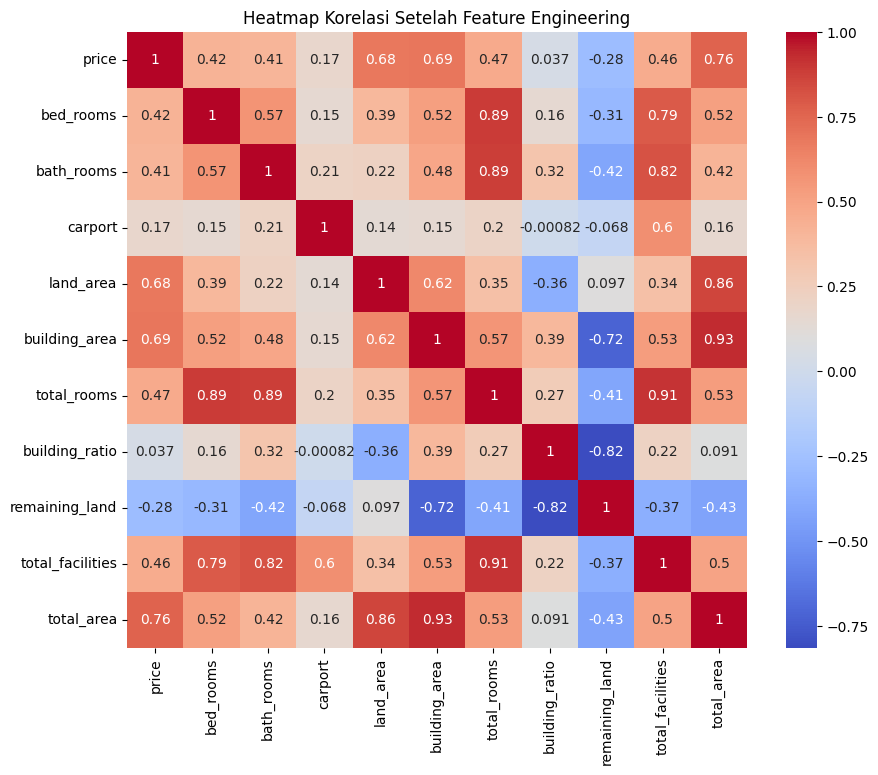

In [ ]:
num_cols = [
        'price',
        'bed_rooms',
        'bath_rooms',
        'carport',
        'land_area',
        'building_area',
        'total_rooms',
        'building_ratio',
        'remaining_land',
        'total_facilities',
        'total_area'
]

corr = df[num_cols].corr()

plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)

plt.title('Heatmap Korelasi Setelah Feature Engineering')
plt.show()

### **4.8 Korelasi Fitur Terhadap Target (Price)**

In [ ]:
corr['price'].sort_values(ascending=False)

,price
price,1.000000
total_area,0.763250
building_area,0.694260
land_area,0.681938
total_rooms,0.465006
total_facilities,0.455566
bed_rooms,0.418820
bath_rooms,0.405396
carport,0.172786
building_ratio,0.037139


# **5. SELEKSI FITUR DAN ENCODING**

### **5.1 Seleksi Fitur**

In [ ]:
df = df[
    [
        'price',
        'district',
        'city',
        'bed_rooms',
        'bath_rooms',
        'carport',
        'land_area',
        'building_area',
        'total_rooms',
        'building_ratio',
        'remaining_land',
        'total_facilities',
        'total_area'
    ]
]

df.head()

,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area,total_rooms,building_ratio,remaining_land,total_facilities,total_area
1,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0,6,2.250000,-125.0,6,325.0
2,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0,6,2.333333,-80.0,6,200.0
3,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0,5,2.000000,-60.0,5,180.0
4,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0,7,1.928571,-52.0,7,164.0
5,2650000000,Tanjung Duren,Jakarta Barat,4,4,0,67.0,149.0,8,2.223881,-82.0,8,216.0


### **5.2 Verifikasi Jumlah Kategori**

In [ ]:
print("Jumlah District :", df['district'].nunique())
print("Jumlah City :", df['city'].nunique())

Jumlah District : 208
Jumlah City : 5


### **5.3 Encoding District**

In [ ]:
le = LabelEncoder()

# District
df['district'] = le.fit_transform(df['district'])

# # City
# df['city'] = le.fit_transform(df['city'])

### **5.4 Encoding City**

In [ ]:
df = pd.get_dummies(
    df,
    columns=['city'],
    drop_first=True
)

### **5.5 Verifikasi Hasil Encoding**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4864 entries, 1 to 9997
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   price                 4864 non-null   int64  
 1   district              4864 non-null   int64  
 2   bed_rooms             4864 non-null   int64  
 3   bath_rooms            4864 non-null   int64  
 4   carport               4864 non-null   int64  
 5   land_area             4864 non-null   float64
 6   building_area         4864 non-null   float64
 7   total_rooms           4864 non-null   int64  
 8   building_ratio        4864 non-null   float64
 9   remaining_land        4864 non-null   float64
 10  total_facilities      4864 non-null   int64  
 11  total_area            4864 non-null   float64
 12  city_Jakarta Pusat    4864 non-null   bool   
 13  city_Jakarta Selatan  4864 non-null   bool   
 14  city_Jakarta Timur    4864 non-null   bool   
 15  city_Jakarta Utara    4864

# **6. PERSIAPAN PEMODELAN**

### **6.1 Menentukan Fitur dan Target**

In [ ]:
# Fitur
X = df.drop('price', axis=1)

# Target
y = df['price']

### **6.2 Pembagian Data Training dan Testing**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

### **6.3 Verifikasi Hasil Pembagian Data**

In [ ]:
print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)

print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (3891, 15)
X_test  : (973, 15)
y_train : (3891,)
y_test  : (973,)


# **7. Hyperparameter Tuning Random Forest**

### **7.1 Menentukan Parameter Uji**

In [ ]:
n_estimators_list = [100, 200, 300, 500, 800]

max_depth_list = [10, 15, 20, 30, None]

min_samples_split_list = [2, 5, 10, 15, 20]

min_samples_leaf_list = [1, 2, 4, 6, 8]

random_state_list = [42]

# Menghitung Total Percobaan
total_percobaan = (
    len(n_estimators_list)
    * len(max_depth_list)
    * len(min_samples_split_list)
    * len(min_samples_leaf_list)
    * len(random_state_list)
)

print("Total Percobaan :", total_percobaan)

Total Percobaan : 625


### **7.2 Melakukan Hyperparameter Tuning**

In [ ]:
hasil = []
counter = 0

for n in n_estimators_list:

    for depth in max_depth_list:

        for split in min_samples_split_list:

            for leaf in min_samples_leaf_list:

                for rs in random_state_list:

                    counter += 1
                    print(f"Percobaan {counter}/{total_percobaan}")

                    rf = RandomForestRegressor(
                        n_estimators=n,
                        max_depth=depth,
                        min_samples_split=split,
                        min_samples_leaf=leaf,
                        random_state=rs
                    )

                    rf.fit(X_train, y_train)

                    y_pred = rf.predict(X_test)

                    mae = mean_absolute_error(y_test,y_pred)

                    mse = mean_squared_error(y_test,y_pred)

                    rmse = np.sqrt(mse)

                    r2 = r2_score(y_test,y_pred)

                    hasil.append([
                        n,
                        depth,
                        split,
                        leaf,
                        rs,
                        mae,
                        mse,
                        rmse,
                        r2
                    ])

Percobaan 1/625
Percobaan 2/625
Percobaan 3/625
Percobaan 4/625
Percobaan 5/625
Percobaan 6/625
Percobaan 7/625
Percobaan 8/625
Percobaan 9/625


KeyboardInterrupt: 

### **7.3 Menampilkan Hasil Hyperparameter Tuning**

In [ ]:
df_hasil = pd.DataFrame(
    hasil,
    columns=[
        'n_estimators',
        'max_depth',
        'min_samples_split',
        'min_samples_leaf',
        'random_state',
        'MAE',
        'MSE',
        'RMSE',
        'R2'
    ]
)

In [ ]:
df_hasil = df_hasil.sort_values(
    by='R2',
    ascending=False
)

df_hasil.head(10)

,n_estimators,max_depth,min_samples_split,min_samples_leaf,random_state,MAE,MSE,RMSE,R2
1,100,10,2,2,42,5.015126e+08,4.668229e+17,6.832444e+08,0.727977
6,100,10,5,2,42,5.020156e+08,4.668713e+17,6.832798e+08,0.727949
7,100,10,5,4,42,5.054149e+08,4.717143e+17,6.868146e+08,0.725127
2,100,10,2,4,42,5.054149e+08,4.717143e+17,6.868146e+08,0.725127
5,100,10,5,1,42,5.050096e+08,4.724054e+17,6.873175e+08,0.724724
0,100,10,2,1,42,5.036842e+08,4.725143e+17,6.873967e+08,0.724661
3,100,10,2,6,42,5.094637e+08,4.762114e+17,6.900807e+08,0.722506
4,100,10,2,8,42,5.152100e+08,4.842442e+17,6.958766e+08,0.717825


### **7.4 Menampilkan Parameter Terbaik**

In [ ]:
parameter_terbaik = df_hasil.iloc[0]


print("n_estimators      :", parameter_terbaik['n_estimators'])
print("max_depth         :", parameter_terbaik['max_depth'])
print("min_samples_split :", parameter_terbaik['min_samples_split'])
print("min_samples_leaf  :", parameter_terbaik['min_samples_leaf'])
print("random_state      :", parameter_terbaik['random_state'])

# **8. Pembangunan Model Random Forest Regressor Final**

### **8.1 Membuat Model Random Forest Regressor**

In [ ]:
rf_final = RandomForestRegressor(
    n_estimators=500,
    max_depth=20,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

### **8.2 Melatih Model**

In [ ]:
rf_final.fit(X_train, y_train)

RandomForestRegressor(max_depth=20, n_estimators=500, random_state=42)

### **8.3 Melakukan Prediksi**

In [ ]:
y_pred = rf_final.predict(X_test)

# **9. EVALUASI MODEL**

### **9.1 Mean Absolute Error (MAE)**

In [ ]:
mae = mean_absolute_error(y_test, y_pred)

print("MAE :", mae)

MAE : 462107565.5008757


### **9.2 Mean Squared Error (MSE)**

In [ ]:
mse = mean_squared_error(y_test, y_pred)

print("MSE :", mse)

MSE : 4.322059933770759e+17


### **9.3 Root Mean Squared Error (RMSE)**

In [ ]:
rmse = np.sqrt(mse)

print("RMSE :", rmse)

RMSE : 657423754.8013275


### **9.4 R-Square (R² Score)**

In [ ]:
r2 = r2_score(y_test, y_pred)

print("R² Score :", r2)

R² Score : 0.7481486721587429


### **9.5 Hasil Evaluasi**

In [ ]:
print(f"MAE  : {mae:.6f}")
print(f"MSE  : {mse:.6f}")
print(f"RMSE : {rmse:.6f}")
print(f"R²   : {r2:.6f}")

MAE  : 462107565.500876
MSE  : 432205993377075904.000000
RMSE : 657423754.801327
R²   : 0.748149


# **10. ANALISIS HASIL PREDIKSI**

### **10.1 Perbandingan Nilai Aktual dan Prediksi**

In [ ]:
hasil_prediksi = pd.DataFrame({
    'Aktual': y_test.values,
    'Prediksi': y_pred
})

hasil_prediksi.head(10)

,Aktual,Prediksi
0,2400000000,2.254139e+09
1,3400000000,2.984259e+09
2,2270000000,2.694904e+09
3,2480000000,2.488504e+09
4,1400000000,2.088949e+09
5,1350000000,2.020625e+09
6,4600000000,4.454013e+09
7,1600000000,2.098879e+09
8,2100000000,3.171750e+09
9,2200000000,2.014029e+09


### **10.2 Visualisasi Hasil Prediksi**

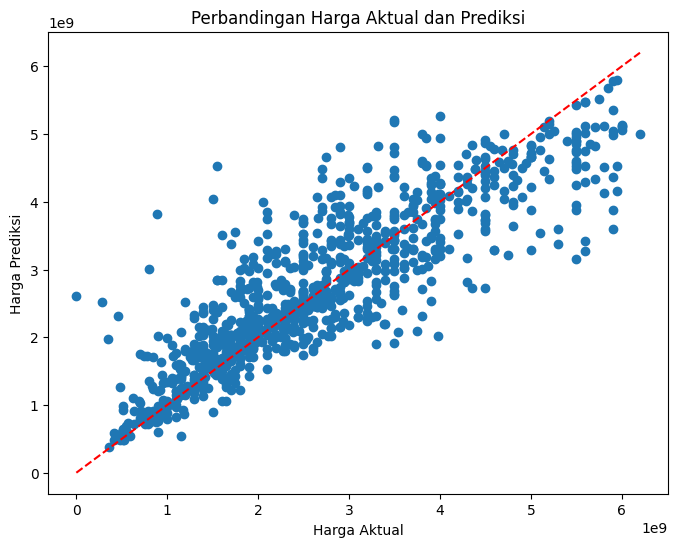

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel('Harga Aktual')
plt.ylabel('Harga Prediksi')
plt.title('Perbandingan Harga Aktual dan Prediksi')

plt.show()

### **10.3 Analisis Feature Importance**

In [ ]:
feature_importance = pd.DataFrame({
    'Fitur': X.columns,
    'Importance': rf_final.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance

,Fitur,Importance
10,total_area,0.642545
0,district,0.080255
4,land_area,0.045547
7,building_ratio,0.034651
8,remaining_land,0.032179
13,city_Jakarta Timur,0.030867
5,building_area,0.025492
9,total_facilities,0.024652
6,total_rooms,0.017363
2,bath_rooms,0.015844
